In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings

warnings.filterwarnings("ignore")

# Deteksi otomatis folder utama proyek ("Data Mining-SPK")
current_dir = Path.cwd()
BASE_DIR = current_dir.parent if current_dir.name == "Notebooks" else current_dir

DATA_DIR = BASE_DIR / "Data"
CLEAN_DIR = DATA_DIR / "Clean"
SKOR_PATH = CLEAN_DIR / "hasil_skor_kriteria.csv"

print("File skor kriteria ketemu?:", SKOR_PATH.exists())

File skor kriteria ketemu?: True


# Load Data & Evaluasi Jumlah Cluster ($k$) dengan Elbow & Silhouette

Fitur yang dipakai clustering hanya C1, C2, dan C3 agar C4 (Performa Akademik) bisa dievaluasi secara independen setelah cluster terbentuk.

=== EVALUASI JUMLAH CLUSTER (k) ===


,k,inertia,silhouette
0,2,76.074900,0.249285
1,3,55.706923,0.279383
2,4,41.581637,0.309859
3,5,32.038081,0.317005
4,6,28.007413,0.273339


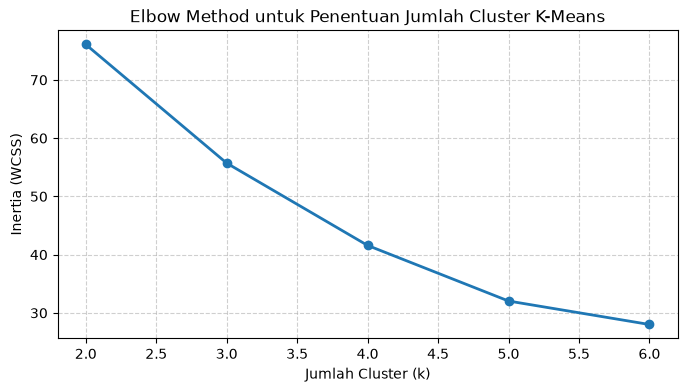

In [6]:
# 1. Baca data skor kriteria
analysis = pd.read_csv(SKOR_PATH)

# 2. Pilih fitur perilaku gaya hidup (C1 - C3)
cluster_features = ["C1_Jasmani", "C2_Mental", "C3_Pola_Belajar"]
cluster_data = analysis[cluster_features].dropna().copy()

# 3. Standarisasi skala fitur (wajib untuk K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_data)

# 4. Uji nilai k dari 2 sampai 6
results = []
max_k = min(6, len(cluster_data) - 1)

for k in range(2, max_k + 1):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    if 1 < len(set(labels)) < len(labels):
        sil = silhouette_score(X_scaled, labels)
    else:
        sil = np.nan
    results.append({"k": k, "inertia": model.inertia_, "silhouette": sil})

cluster_eval = pd.DataFrame(results)
print("=== EVALUASI JUMLAH CLUSTER (k) ===")
display(cluster_eval)

# 5. Visualisasi Elbow Method
if not cluster_eval.empty:
    plt.figure(figsize=(8, 4))
    plt.plot(cluster_eval["k"], cluster_eval["inertia"], marker="o", linewidth=2)
    plt.xlabel("Jumlah Cluster (k)")
    plt.ylabel("Inertia (WCSS)")
    plt.title("Elbow Method untuk Penentuan Jumlah Cluster K-Means")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.show()

# Eksekusi K-Means ($k=3$), Centroid Alternatif SPK, & Perbandingan C4 Akademik

In [7]:
K_PILIHAN = 3  # Bisa disesuaikan setelah melihat grafik Elbow di atas

if len(cluster_data) > K_PILIHAN >= 2:
    final_kmeans = KMeans(n_clusters=K_PILIHAN, random_state=42, n_init=10)
    cluster_labels = final_kmeans.fit_predict(X_scaled)

    # Gabungkan label cluster ke dataset utama
    clustered = analysis.loc[cluster_data.index].copy()
    clustered["Cluster"] = cluster_labels + 1  # Mulai dari Cluster 1

    print("=== JUMLAH RESPONDEN PER CLUSTER ===")
    display(clustered["Cluster"].value_counts().sort_index().to_frame("Jumlah Responden"))

    # Menampilkan Centroid (Rata-rata asli skala 1-5) sebagai Alternatif SPK (A1, A2, A3)
    centroid_spk = clustered.groupby("Cluster")[["C1_Jasmani", "C2_Mental", "C3_Pola_Belajar", "C4_Akademik"]].mean().round(3)
    centroid_spk.index = [f"A{i} (Cluster {i})" for i in centroid_spk.index]
    
    print("\n=== MATRIKS CENTROID K-MEANS (ALTERNATIF UNTUK SPK SAW) ===")
    display(centroid_spk)

    print("\n=== RINGKASAN PERFORMA AKADEMIK (C4) PER CLUSTER ===")
    display(clustered.groupby("Cluster")["C4_Akademik"].agg(["count", "mean", "median", "std"]).round(3))
else:
    print("Jumlah data belum mencukupi untuk K_PILIHAN ini.")

=== JUMLAH RESPONDEN PER CLUSTER ===


,Jumlah Responden
Cluster,
1,15
2,6
3,16



=== MATRIKS CENTROID K-MEANS (ALTERNATIF UNTUK SPK SAW) ===


,C1_Jasmani,C2_Mental,C3_Pola_Belajar,C4_Akademik
A1 (Cluster 1),3.200,3.040,3.113,4.383
A2 (Cluster 2),2.000,1.533,2.125,4.319
A3 (Cluster 3),3.075,2.625,1.950,4.328



=== RINGKASAN PERFORMA AKADEMIK (C4) PER CLUSTER ===


,count,mean,median,std
Cluster,,,,
1,15,4.383,4.667,0.570
2,6,4.319,4.125,0.423
3,16,4.328,4.500,0.455


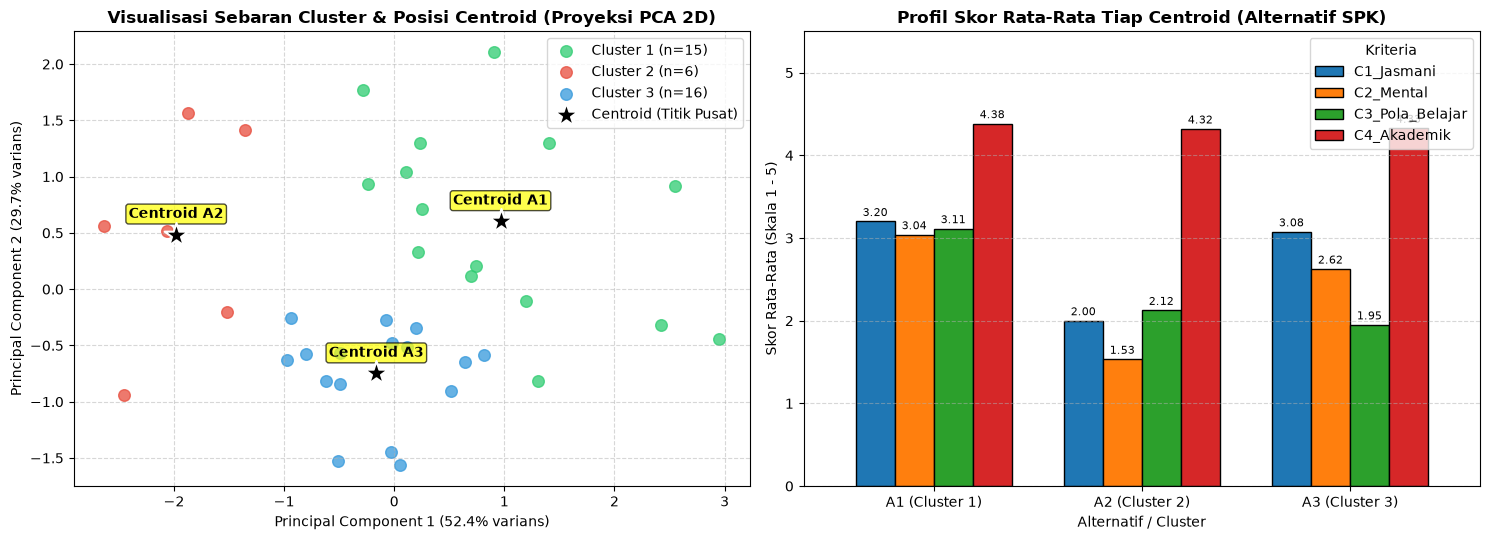

In [8]:
from sklearn.decomposition import PCA

# 1. Reduksi 3 dimensi (C1, C2, C3) ke 2 dimensi pakai PCA untuk visualisasi scatter
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Transformasi titik centroid (dalam ruang scaled) ke ruang PCA 2D
centroids_scaled = final_kmeans.cluster_centers_
centroids_pca = pca.transform(centroids_scaled)

# 2. Buat 2 subplot berdampingan: Kiri (Scatter + Centroid), Kanan (Bar Chart Profil Centroid)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# --- PLOT 1: SCATTER PLOT CLUSTER & CENTROID (PCA 2D) ---
colors = ["#2ecc71", "#e74c3c", "#3498db", "#f1c40f"]
for i in range(K_PILIHAN):
    mask = (cluster_labels == i)
    axes[0].scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=70,
        alpha=0.75,
        color=colors[i % len(colors)],
        label=f"Cluster {i+1} (n={mask.sum()})"
    )

# Plot titik pusat Centroid dengan tanda bintang besar
axes[0].scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    s=320,
    c="black",
    marker="*",
    edgecolors="white",
    linewidths=1.5,
    zorder=10,
    label="Centroid (Titik Pusat)"
)

# Beri label teks A1, A2, A3 di dekat masing-masing bintang centroid
for i, (cx, cy) in enumerate(centroids_pca):
    axes[0].annotate(
        f"Centroid A{i+1}",
        (cx, cy),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontweight="bold",
        fontsize=10,
        bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.7)
    )

axes[0].set_title("Visualisasi Sebaran Cluster & Posisi Centroid (Proyeksi PCA 2D)", fontweight="bold")
axes[0].set_xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% varians)")
axes[0].set_ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% varians)")
axes[0].legend(loc="best")
axes[0].grid(True, linestyle="--", alpha=0.5)

# --- PLOT 2: PERBANDINGAN SKOR RATA-RATA TIAP CENTROID (SKALA ASLI 1-5) ---
centroid_plot_df = clustered.groupby("Cluster")[["C1_Jasmani", "C2_Mental", "C3_Pola_Belajar", "C4_Akademik"]].mean()
centroid_plot_df.index = [f"A{i} (Cluster {i})" for i in centroid_plot_df.index]

centroid_plot_df.plot(kind="bar", ax=axes[1], width=0.75, edgecolor="black")
axes[1].set_title("Profil Skor Rata-Rata Tiap Centroid (Alternatif SPK)", fontweight="bold")
axes[1].set_xlabel("Alternatif / Cluster")
axes[1].set_ylabel("Skor Rata-Rata (Skala 1 - 5)")
axes[1].set_ylim(0, 5.5)
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Kriteria", loc="upper right")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

# Tambahkan angka di atas setiap batang bar chart
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", fontsize=8, padding=2)

plt.tight_layout()
plt.show()

Penjelasan mengenai masing masing Cluster :
A1/Cluster 1 = merupakan hasil profil yang maksimal
A2/Cluster 2 = merupakan hasil profil yang rentang/buruk/kurang
A3/Cluster 3 = merupakan hasil rata-rata/sedang

# Simpan Output Hasil Clustering & Centroid ke Folder Data/Clean

In [9]:
OUTPUT_CLUSTER_PATH = CLEAN_DIR / "hasil_clustering_kmeans.csv"
OUTPUT_CENTROID_PATH = CLEAN_DIR / "centroid_alternatif_spk.csv"

clustered.to_csv(OUTPUT_CLUSTER_PATH, index=False)
centroid_spk.to_csv(OUTPUT_CENTROID_PATH, index=True)

print("File hasil K-Means berhasil disimpan di:")
print("->", OUTPUT_CLUSTER_PATH)
print("->", OUTPUT_CENTROID_PATH)

File hasil K-Means berhasil disimpan di:
-> c:\Users\daniel\Desktop\Data Mining-SPK\Data\Clean\hasil_clustering_kmeans.csv
-> c:\Users\daniel\Desktop\Data Mining-SPK\Data\Clean\centroid_alternatif_spk.csv
